<a href="https://colab.research.google.com/github/NOrdyna/IS201WebDevProject/blob/main/HEMO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms

# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Data augmentations (ColorJitter helps combat lighting bias in your sessions)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3. Load full dataset from the correct path in Google Drive
data_dir = '/content/drive/MyDrive/HEMO Project/HEMOIMAGES'

# We create two datasets: one for training (with augmentations) and one for validation (clean)
train_full_dataset = datasets.ImageFolder(root=data_dir, transform=train_transforms)
val_full_dataset = datasets.ImageFolder(root=data_dir, transform=val_transforms)

print(f"Classes found: {train_full_dataset.classes}")
total_images = len(train_full_dataset)
print(f"Total images found: {total_images}")

# 4. Automatically split into 80% train and 20% validation indices
train_size = int(0.8 * total_images)
indices = torch.randperm(total_images).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(train_full_dataset, train_indices)
val_dataset = Subset(val_full_dataset, val_indices)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# 5. Initialize Pretrained ResNet18 for Fine-Tuning
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

num_classes = len(train_full_dataset.classes)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# 6. Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 7. Training & Validation Loop
num_epochs = 10

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total_train
    epoch_acc = correct_train / total_train

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    val_acc = correct_val / total_val if total_val > 0 else 0.0

    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f} | Val Acc: {val_acc:.4f}")

Using device: cuda
Classes found: ['FIX deficient', 'FV deficient ', 'FVIII deficient', 'FXI deficient ', 'Normal plasma']
Total images found: 997
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 207MB/s]


Epoch [1/10] | Loss: 0.8162 | Train Acc: 0.6587 | Val Acc: 0.6250
Epoch [2/10] | Loss: 0.5875 | Train Acc: 0.7440 | Val Acc: 0.7500
Epoch [3/10] | Loss: 0.4721 | Train Acc: 0.7905 | Val Acc: 0.7550
Epoch [4/10] | Loss: 0.3902 | Train Acc: 0.8269 | Val Acc: 0.8550
Epoch [5/10] | Loss: 0.3698 | Train Acc: 0.8432 | Val Acc: 0.7800
Epoch [6/10] | Loss: 0.3064 | Train Acc: 0.8657 | Val Acc: 0.8350
Epoch [7/10] | Loss: 0.3078 | Train Acc: 0.8745 | Val Acc: 0.7900
Epoch [8/10] | Loss: 0.2833 | Train Acc: 0.8959 | Val Acc: 0.8450
Epoch [9/10] | Loss: 0.2638 | Train Acc: 0.8908 | Val Acc: 0.8100
Epoch [10/10] | Loss: 0.2682 | Train Acc: 0.8883 | Val Acc: 0.7050


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Data augmentations (ColorJitter helps combat lighting bias in your sessions)
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3. Load full dataset from Google Drive
data_dir = '/content/drive/MyDrive/HEMO Project/HEMOIMAGES'

train_full_dataset = datasets.ImageFolder(root=data_dir, transform=train_transforms)
val_full_dataset = datasets.ImageFolder(root=data_dir, transform=val_transforms)

class_names = train_full_dataset.classes
print(f"Classes found: {class_names}")
total_images = len(train_full_dataset)
print(f"Total images found: {total_images}")

# 4. Automatically split into 80% train and 20% validation indices
train_size = int(0.8 * total_images)
indices = torch.randperm(total_images).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(train_full_dataset, train_indices)
val_dataset = Subset(val_full_dataset, val_indices)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# 5. Initialize Pretrained ResNet18 for Fine-Tuning
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

num_classes = len(class_names)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# 6. Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 7. Training Loop with Early Stopping & Best Model Saving
num_epochs = 15
best_val_acc = 0.0

print("\n--- Starting Training ---")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total_train
    epoch_acc = correct_train / total_train

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    val_acc = correct_val / total_val if total_val > 0 else 0.0

    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f} | Val Acc: {val_acc:.4f}")

    # Save the model if validation accuracy improves (Early Stopping checkpoint)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_clotting_model.pth')
        print(f"  --> Saved new best model with Val Acc: {val_acc:.4f}")

print(f"\nTraining complete! Best Validation Accuracy: {best_val_acc:.4f}")

# 8. Final Evaluation & Confusion Matrix
print("\n--- Evaluating Best Model on Validation Set ---")
model.load_state_dict(torch.load('best_clotting_model.pth'))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate classification report and confusion matrix
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

print("Confusion Matrix (Rows = Actual, Columns = Predicted):")
print(confusion_matrix(all_labels, all_preds))

Using device: cuda
Classes found: ['FIX deficient', 'FV deficient ', 'FVIII deficient', 'FXI deficient ', 'Normal plasma']
Total images found: 997

--- Starting Training ---
Epoch [1/15] | Loss: 0.8434 | Train Acc: 0.6700 | Val Acc: 0.5150
  --> Saved new best model with Val Acc: 0.5150
Epoch [2/15] | Loss: 0.4428 | Train Acc: 0.7930 | Val Acc: 0.7400
  --> Saved new best model with Val Acc: 0.7400
Epoch [3/15] | Loss: 0.3843 | Train Acc: 0.8281 | Val Acc: 0.6400
Epoch [4/15] | Loss: 0.4279 | Train Acc: 0.8269 | Val Acc: 0.8000
  --> Saved new best model with Val Acc: 0.8000
Epoch [5/15] | Loss: 0.4021 | Train Acc: 0.8068 | Val Acc: 0.7300
Epoch [6/15] | Loss: 0.3240 | Train Acc: 0.8620 | Val Acc: 0.6650
Epoch [7/15] | Loss: 0.2692 | Train Acc: 0.8795 | Val Acc: 0.7550
Epoch [8/15] | Loss: 0.2422 | Train Acc: 0.8996 | Val Acc: 0.8800
  --> Saved new best model with Val Acc: 0.8800
Epoch [9/15] | Loss: 0.2248 | Train Acc: 0.9134 | Val Acc: 0.8450
Epoch [10/15] | Loss: 0.2469 | Train Acc

In [ ]:
# Nov 3, 2026

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, models, transforms
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# 2. Data augmentations
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3. Load full dataset from Google Drive
data_dir = '/content/drive/MyDrive/HEMO Project/HEMOIMAGES'

train_full_dataset = datasets.ImageFolder(root=data_dir, transform=train_transforms)
val_full_dataset = datasets.ImageFolder(root=data_dir, transform=val_transforms)

class_names = train_full_dataset.classes
print(f"Classes found ({len(class_names)} total): {class_names}")
total_images = len(train_full_dataset)
print(f"Total images found: {total_images}")

# 4. Automatically split into 80% train and 20% validation indices
train_size = int(0.8 * total_images)
indices = torch.randperm(total_images).tolist()

train_indices = indices[:train_size]
val_indices = indices[train_size:]

train_dataset = Subset(train_full_dataset, train_indices)
val_dataset = Subset(val_full_dataset, val_indices)

# Optimized DataLoaders with background pre-fetching to prevent Drive freezes
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# 5. Initialize Pretrained ResNet18 for Fine-Tuning (Dynamic class count)
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

num_classes = len(class_names)
model.fc = nn.Linear(model.fc.in_features, num_classes)
model = model.to(device)

# 6. Loss and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 7. Training Loop with Early Stopping & Best Model Saving
num_epochs = 15
best_val_acc = 0.0

print("\n--- Starting Training ---")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total_train += labels.size(0)
        correct_train += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / total_train
    epoch_acc = correct_train / total_train

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, predicted = outputs.max(1)
            total_val += labels.size(0)
            correct_val += predicted.eq(labels).sum().item()

    val_acc = correct_val / total_val if total_val > 0 else 0.0

    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f} | Val Acc: {val_acc:.4f}")

    # Save the 6-class model checkpoint when validation accuracy improves
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best_clotting_model_6class.pth')
        print(f"  --> Saved new best 6-class model with Val Acc: {val_acc:.4f}")

print(f"\nTraining complete! Best Validation Accuracy: {best_val_acc:.4f}")

# 8. Final Evaluation & Confusion Matrix
print("\n--- Evaluating Best Model on Validation Set ---")
model.load_state_dict(torch.load('best_clotting_model_6class.pth'))
model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, predicted = outputs.max(1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Generate classification report and confusion matrix
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))

print("Confusion Matrix (Rows = Actual, Columns = Predicted):")
print(confusion_matrix(all_labels, all_preds))

Using device: cuda
Classes found (6 total): ['FIX deficient', 'FV deficient', 'FVIII deficient', 'FX deficient', 'FXI deficient ', 'Normal plasma']
Total images found: 1057

--- Starting Training ---
Epoch [1/15] | Loss: 0.9570 | Train Acc: 0.6107 | Val Acc: 0.6604
  --> Saved new best 6-class model with Val Acc: 0.6604
Epoch [2/15] | Loss: 0.5796 | Train Acc: 0.7361 | Val Acc: 0.6179
Epoch [3/15] | Loss: 0.5379 | Train Acc: 0.7467 | Val Acc: 0.8019
  --> Saved new best 6-class model with Val Acc: 0.8019
Epoch [4/15] | Loss: 0.5195 | Train Acc: 0.7680 | Val Acc: 0.7500
Epoch [5/15] | Loss: 0.4326 | Train Acc: 0.8059 | Val Acc: 0.6651
Epoch [6/15] | Loss: 0.4505 | Train Acc: 0.7882 | Val Acc: 0.5142
Epoch [7/15] | Loss: 0.3961 | Train Acc: 0.8130 | Val Acc: 0.7170
Epoch [8/15] | Loss: 0.3345 | Train Acc: 0.8462 | Val Acc: 0.8113
  --> Saved new best 6-class model with Val Acc: 0.8113
Epoch [9/15] | Loss: 0.3636 | Train Acc: 0.8414 | Val Acc: 0.7689
Epoch [10/15] | Loss: 0.3632 | Train A

In [2]:
# NOVEMBER 10, 2026 Work. I am trying spatial data augmentation to see if we can fix the GRAD-CAM for Normal Plasma (NP) because the hot spots from last week were all in the same place for every NP image which is unprobable.

print("Starting training with spatial data augmentations...")
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)

        # FIX IS HERE:
        correct_train += (preds == labels).sum().item()
        total_train += labels.size(0)

    train_loss = running_loss / total_train
    train_acc = correct_train / total_train

    # Validation phase
    model.eval()
    correct_val = 0
    total_val = 0
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            correct_val += (preds == labels).sum().item()
            total_val += labels.size(0)

    val_acc = correct_val / total_val
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {train_acc*100:.2f}% | Val Acc: {val_acc*100:.2f}%")

    # Save best model
    if val_acc > best_acc:
        best_acc = val_acc
        torch.save(model.state_dict(), 'best_clotting_model_6class.pth')
        print("--> Saved new best model checkpoint!")

print(f"Training complete! Best Validation Accuracy: {best_acc*100:.2f}%")

Starting training with spatial data augmentations...
Epoch [1/10] | Train Loss: 0.7757 | Train Acc: 71.60% | Val Acc: 43.87%
--> Saved new best model checkpoint!
Epoch [2/10] | Train Loss: 0.5353 | Train Acc: 77.28% | Val Acc: 72.17%
--> Saved new best model checkpoint!
Epoch [3/10] | Train Loss: 0.5243 | Train Acc: 77.40% | Val Acc: 80.19%
--> Saved new best model checkpoint!
Epoch [4/10] | Train Loss: 0.3915 | Train Acc: 82.01% | Val Acc: 52.83%
Epoch [5/10] | Train Loss: 0.4266 | Train Acc: 82.37% | Val Acc: 62.26%
Epoch [6/10] | Train Loss: 0.4068 | Train Acc: 82.60% | Val Acc: 52.83%
Epoch [7/10] | Train Loss: 0.3480 | Train Acc: 85.09% | Val Acc: 82.08%
--> Saved new best model checkpoint!
Epoch [8/10] | Train Loss: 0.3165 | Train Acc: 87.34% | Val Acc: 60.85%
Epoch [9/10] | Train Loss: 0.3615 | Train Acc: 86.51% | Val Acc: 68.40%
Epoch [10/10] | Train Loss: 0.2939 | Train Acc: 88.52% | Val Acc: 77.83%
Training complete! Best Validation Accuracy: 82.08%


In [3]:
import os
import torch
import torch.nn.functional as F
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# 1. Setup device and load your newly trained model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
num_classes = 6  # FIX, FV, FVIII, FX, FXI, Normal plasma

model = models.resnet18(weights=None)
model.fc = torch.nn.Linear(model.fc.in_features, num_classes)
model.load_state_dict(torch.load('best_clotting_model_6class.pth', map_location=device))
model = model.to(device)
model.eval()

# 2. Target layer for ResNet18 (last convolutional layer)
target_layer = model.layer4[-1]

activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output.detach()

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0].detach()

target_layer.register_forward_hook(forward_hook)
target_layer.register_full_backward_hook(backward_hook)

# 3. Set paths for Normal plasma folder and output directory
normal_dir = '/content/drive/MyDrive/HEMO Project/HEMOIMAGES/Normal plasma'
output_dir = '/content/drive/MyDrive/HEMO Project/GradCAM_Normal_Augmented'
os.makedirs(output_dir, exist_ok=True)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

class_names = ['FIX deficient', 'FV deficient', 'FVIII deficient', 'FX deficient', 'FXI deficient ', 'Normal plasma']

print("Generating new Grad-CAM heatmaps for Normal plasma with augmented weights...")
count = 0
for img_name in os.listdir(normal_dir):
    if not img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
        continue

    img_path = os.path.join(normal_dir, img_name)
    orig_img = Image.open(img_path).convert('RGB')
    input_tensor = transform(orig_img).unsqueeze(0).to(device)

    # Forward pass
    output = model(input_tensor)
    pred_idx = output.argmax(dim=1).item()
    conf = F.softmax(output, dim=1)[0, pred_idx].item()

    # Backward pass for Grad-CAM
    model.zero_grad()
    class_loss = output[0, pred_idx]
    class_loss.backward()

    # Generate heatmap
    pooled_grads = gradients.mean(dim=[0, 2, 3], keepdim=True)
    weighted_activations = activations * pooled_grads
    heatmap = weighted_activations.sum(dim=1).squeeze().cpu().numpy()

    heatmap = np.maximum(heatmap, 0)
    if heatmap.max() != 0:
        heatmap /= heatmap.max()

    # Resize and overlay
    orig_np = np.array(orig_img.resize((224, 224)))
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    superimposed = cv2.addWeighted(orig_np, 0.6, heatmap_colored, 0.4, 0)

    # Save output comparison image
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(orig_np)
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB))
    axes[1].set_title(f"Pred: {class_names[pred_idx]}\nConf: {conf*100:.2f}%")
    axes[1].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, f"gradcam_{img_name}"))
    plt.close()
    count += 1

print(f"Done! Generated and saved {count} new Grad-CAM heatmaps to {output_dir}")


Generating new Grad-CAM heatmaps for Normal plasma with augmented weights...
Done! Generated and saved 300 new Grad-CAM heatmaps to /content/drive/MyDrive/HEMO Project/GradCAM_Normal_Augmented


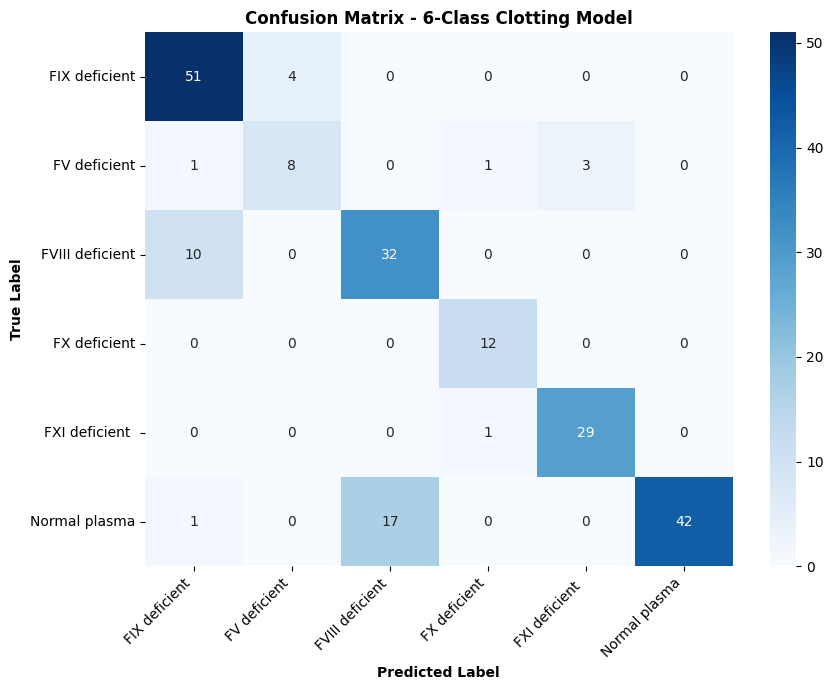


Classification Report:
                 precision    recall  f1-score   support

  FIX deficient       0.81      0.93      0.86        55
   FV deficient       0.67      0.62      0.64        13
FVIII deficient       0.65      0.76      0.70        42
   FX deficient       0.86      1.00      0.92        12
 FXI deficient        0.91      0.97      0.94        30
  Normal plasma       1.00      0.70      0.82        60

       accuracy                           0.82       212
      macro avg       0.82      0.83      0.81       212
   weighted avg       0.84      0.82      0.82       212



In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 1. Ensure the model is in evaluation mode
model.eval()

all_preds = []
all_labels = []

# 2. Collect predictions across the entire validation set
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# 3. Compute confusion matrix
cm = confusion_matrix(all_labels, all_preds)

# 4. Plot heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted Label', fontweight='bold')
plt.ylabel('True Label', fontweight='bold')
plt.title('Confusion Matrix - 6-Class Clotting Model', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 5. Print detailed precision, recall, and f1-score per class
print("\nClassification Report:")
print(classification_report(all_labels, all_preds, target_names=class_names))